# Keypoint estimation — quickstart

**Keypoint estimation** finds named landmarks — body joints, facial points, the corners of a part — and returns an (x, y) position for each. The demo locates the three corners of a triangle (`apex`, `left`, `right`). This task expects **one labelled object per image**.

This notebook runs the **whole pipeline in about ten cells**. The other notebooks slow down and explain each step.

**Data → Train → Evaluate → Predict** &nbsp;·&nbsp; runs on CPU in about 2 minutes with the `quick` preset.

In [1]:
# Run this cell first.
# On Colab it clones the kit and installs what's missing; locally it just finds the repo root.
import os, sys, subprocess
from pathlib import Path

if "google.colab" in sys.modules and not Path("cvkit").exists():
    subprocess.run(["git", "clone", "-q", "https://github.com/standungan/computer-vision-starter-kit"], check=True)
    os.chdir("computer-vision-starter-kit")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pyyaml", "scikit-learn", "gradio"], check=True)
while not Path("cvkit").exists() and Path.cwd() != Path.cwd().parent:
    os.chdir(Path.cwd().parent)          # notebooks live 3 folders below the repo root
sys.path.insert(0, os.getcwd())
print("working in", Path.cwd().name)

working in computer-vision-starter-kit


In [2]:
%config InlineBackend.figure_format = "jpeg"
%config InlineBackend.print_figure_kwargs = {"bbox_inches": "tight", "pil_kwargs": {"quality": 90}}   # keeps saved notebooks small

from PIL import Image

from cvkit.config import load_config
from cvkit.synthetic import make_demo_data
from cvkit.utils import seed_everything

# quick.yaml = small synthetic demo, runs on a laptop CPU in minutes.
# Swap in default.yaml (bigger, pretrained) or your own config + data when you're ready.
CONFIG = "tasks/keypoints/configs/quick.yaml"
cfg = load_config(CONFIG)
seed_everything(cfg["seed"])

if not Path(cfg["data"]["root"]).exists():          # first run: create the demo dataset
    make_demo_data("keypoints", cfg)
print("task:", "keypoints", "| data:", cfg["data"]["root"], "| outputs:", cfg["output"]["dir"])

task: keypoints | data: data/demo/keypoints | outputs: outputs/keypoints_quick


## 1 · The data
A few examples, with their labels:

keypoints: ['apex', 'left', 'right']


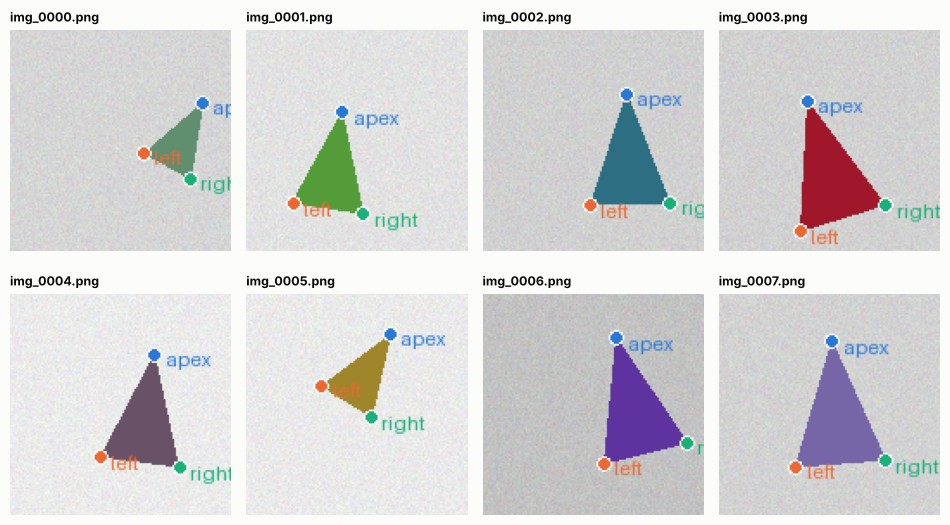

In [3]:
from PIL import Image
from cvkit.viz import draw_keypoints, image_grid
from tasks.keypoints.data import build_datasets

ds = build_datasets(cfg)
names, items = ds["keypoint_names"], ds["items"]
print("keypoints:", names)
shown = [draw_keypoints(Image.open(it["path"]), [(it["keypoints"][i], it["keypoints"][i + 1]) for i in range(0, len(it["keypoints"]), 3)], names) for it in items[:8]]
_ = image_grid(shown, [Path(it["path"]).name for it in items[:8]], cols=4, cell=2.4)

## 2 · Train
`train(cfg)` is the same function the command line calls: `python -m cvkit keypoints train --quick`. It prints one line per epoch and saves the best model.

In [4]:
from tasks.keypoints.train import train

result = train(cfg)

arch: resnet18 | keypoints (3): ['apex', 'left', 'right']
device: cpu | parameters: 15,373,123 total, 15,373,123 trainable (100.0%)


epoch   1/20 | train_loss 6.9139 | val nme=0.129 pck=0.132 mean_err_px=16.454 | 5.1s  <- best


epoch   2/20 | train_loss 5.5562 | val nme=0.085 pck=0.236 mean_err_px=10.818 | 5.0s  <- best


epoch   3/20 | train_loss 4.9111 | val nme=0.047 pck=0.611 mean_err_px=5.979 | 4.9s  <- best


epoch   4/20 | train_loss 4.5452 | val nme=0.034 pck=0.792 mean_err_px=4.336 | 5.2s  <- best


...

epoch  16/20 | train_loss 4.1964 | val nme=0.008 pck=1.000 mean_err_px=1.060 | 5.3s  <- best


epoch  17/20 | train_loss 4.2002 | val nme=0.009 pck=1.000 mean_err_px=1.096 | 5.0s


epoch  18/20 | train_loss 4.1998 | val nme=0.008 pck=1.000 mean_err_px=0.999 | 4.8s  <- best


epoch  19/20 | train_loss 4.1893 | val nme=0.008 pck=1.000 mean_err_px=0.991 | 4.9s  <- best


epoch  20/20 | train_loss 4.2012 | val nme=0.008 pck=1.000 mean_err_px=1.011 | 4.8s
best val nme = 0.0077 (epoch 19) -> outputs/keypoints_quick/checkpoints/best.pt


## 3 · Evaluate on the held-out test split
Images the model never trained on, and never used to pick its best epoch.

In [5]:
from tasks.keypoints.evaluate import evaluate

metrics = evaluate(cfg)

NME 0.0080 (of image side) | mean error 1.02px at 128px | PCK@0.05 1.000 (48 test images)
  apex           PCK 1.000   NME 0.0068
  left           PCK 1.000   NME 0.0086
  right          PCK 1.000   NME 0.0087
reports -> outputs/keypoints_quick/reports


pck_curve.png


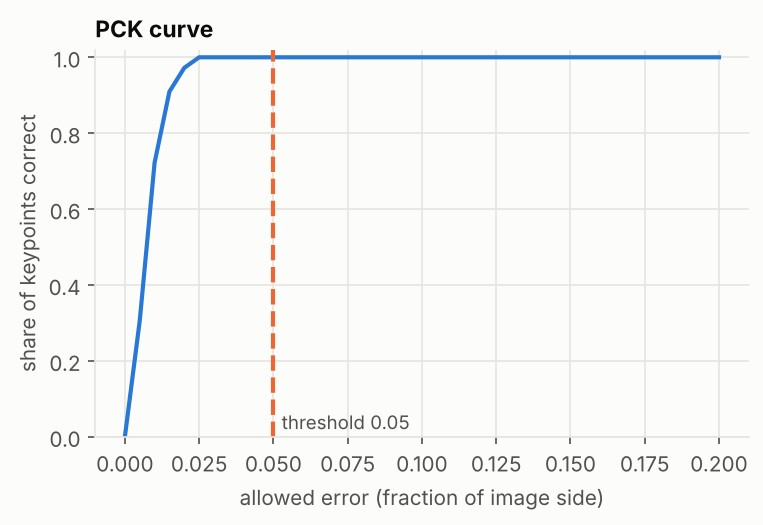

error_per_keypoint.png


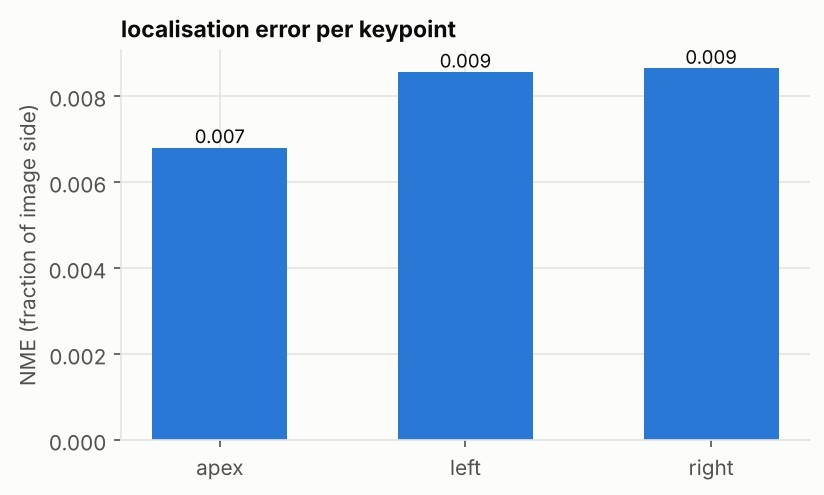

predictions.png


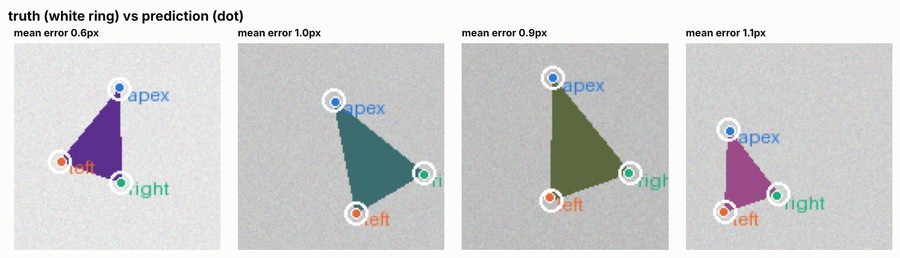

worst_images.png


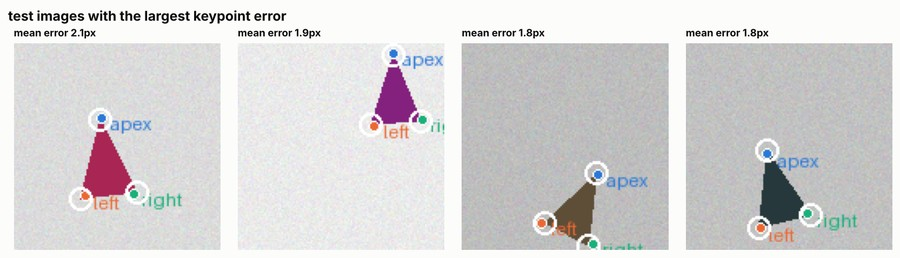

In [6]:
from cvkit.viz import show_image

reports = Path(cfg["output"]["dir"]) / "reports"
for name in ['pck_curve.png', 'error_per_keypoint.png', 'predictions.png', 'worst_images.png']:
    print(name)
    show_image(reports / name)

**Reading it:** `predictions.png` draws the prediction as coloured dots and the truth as white rings — a dot inside its ring is a hit. `pck_curve.png` shows the share of keypoints within a given distance of the truth, so you see the whole accuracy picture at once.

## 4 · Predict
`Predictor.predict` returns one dict per keypoint, with x and y in the image's own pixels:

[{'name': 'apex', 'x': 65.06741333007812, 'y': 27.912015914916992, 'confidence': 0.31961458921432495}, {'name': 'left', 'x': 29.43640899658203, 'y': 73.41297912597656, 'confidence': 0.3204544484615326}, {'name': 'right', 'x': 66.3170394897461, 'y': 86.22358703613281, 'confidence': 0.3148319125175476}]


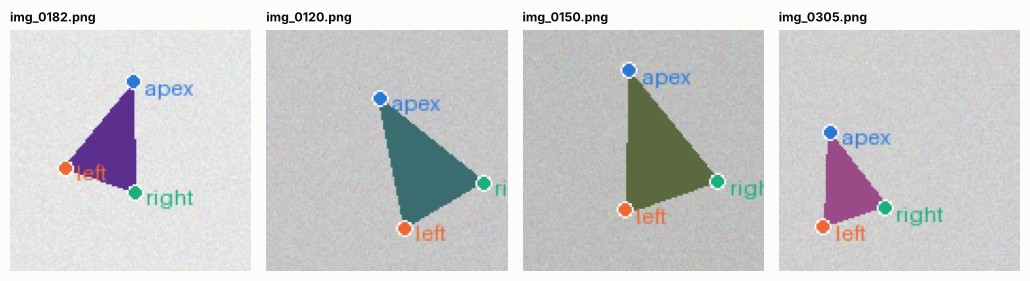

In [7]:
from cvkit.viz import image_grid
from tasks.keypoints.predict import Predictor
from tasks.keypoints.data import test_image_paths

predictor = Predictor.from_config(cfg)
paths = test_image_paths(cfg, 4)
pts = [predictor.predict(p) for p in paths]
print(pts[0])
_ = image_grid([predictor.visualize(p, q) for p, q in zip(paths, pts)], [Path(p).name for p in paths], cols=4, cell=2.6)

## What next?
* **[01_data](01_data.ipynb)** — look at the data and augmentation properly
* **[02_train_and_evaluate](02_train_and_evaluate.ipynb)** — learning curves, how to read the metrics, experiments
* **[03_predict_and_deploy](03_predict_and_deploy.ipynb)** — your own images, the demo app, deployment
* Read the task's [README](../README.md) · use your own data: [data formats](../../../docs/data-formats.md)